# Week 5 practical: evaluating a swing-up controller from samples

**240MAR45 Reinforcement Learning in Robotics** | MSc Automatic Control and Robotics, UPC

**Where to run it.** In Google Colab: open colab.research.google.com, then File > Upload
notebook, and pick this `.ipynb`. Nothing to install. Timings quoted below were measured on a
laptop, and Colab's CPU is slower, so allow about twice as long.

Last week, we deleted the state. Today, it returns, along with the question: **what does it cost to evaluate a fixed controller from every state when the model is unavailable and all we can do is run it?** We will use the Week 2 swing-up controller for the torque-limited pendulum, represented as a 961-state Markov chain. Its exact value function can be computed by solving a linear system, giving us ground truth against which to measure every approximation. You will first derive TD(0) as the Robbins–Monro stochastic approximation it is, quantify the impact of the step-size schedule, and then introduce eligibility traces, tuning the step size \(\alpha\) and trace-decay parameter \(\lambda\) together.

## Objectives

1. Read TD(0) as stochastic approximation on $h(V) = \mathcal{T}^\pi V - V$, and implement it.
2. Measure the exchange a step-size schedule makes between speed and noise floor, on a scalar
   problem first and then inside TD(0), and see where the schedule of the convergence theorem
   lands.
3. See what TD does to states its data never reach, and measure why Monte Carlo pays in variance
   for its unbiased target.
4. Implement TD($\lambda$) with replacing traces and show that both ends of the spectrum lose to
   the middle, once $\alpha$ and $\lambda$ are tuned jointly.

## Session plan

Everything here is done in the session, and there is no homework. The quiz at the end is the only
thing evaluated.

| Part | Minutes |
|------|---------|
| 1 to 3. Smoke test, recap, the pre-written chain | 10 |
| 4. Robbins–Monro on a scalar problem (Checkpoint 1) | 7 |
| 5. Blanked core A, the TD(0) update | 8 |
| 6. What the step size costs inside TD(0) (Checkpoint 2) | 9 |
| 7. Coverage, the states the data never reach (Checkpoint 3) | 6 |
| 8. The Monte Carlo target and the TD target, side by side (Checkpoint 4) | 5 |
| 9. Blanked core B, TD($\lambda$) with replacing traces | 10 |
| 10. The joint sweep over $\alpha$ and $\lambda$ (Checkpoints 5 and 6) | 13 |
| 11. Analysis | 7 |
| The quiz, on the university course page | 15 |

The two heavy cells are the step-size run of section 6 (32 learners for half a million
transitions each) and the joint sweep of section 10 (400 learners), about 30 seconds each on a
laptop, and the coverage run of section 7 takes about 12. Start each and read the next cell while
it runs. Everything else finishes in a second or two. If you finish early, the optional long run
at the end of section 6 reproduces the figure of the notes at its full budget, and challenge
problem 5.6 of the notes evaluates a controller that is being retuned. Both are formative, so nobody collects them.

## 1. Smoke test (run this first)

If any line below fails, raise your hand before reading further.

In [ ]:
import sys
import time

t0 = time.time()

import numpy as np
import scipy
import scipy.sparse as sp
from scipy.linalg import expm, solve_discrete_are
from scipy.sparse.linalg import spsolve
import matplotlib
import matplotlib.pyplot as plt

print(f"python      {sys.version.split()[0]}")
print(f"numpy       {np.__version__}")
print(f"scipy       {scipy.__version__}")
print(f"matplotlib  {matplotlib.__version__}")

# One random rollout: the course pendulum (m = l = 1, b = 0.1, u_max = 5 < m g l) released near
# the bottom under random saturated torques for 5 s. Section 3 builds the chain from the same plant.
rng = np.random.default_rng(0)
th, om = 0.1, 0.0
for _ in range(50):
    u = np.clip(rng.normal(0.0, 3.0), -5.0, 5.0)
    for _ in range(10):
        om += 0.01 * (u - 0.1 * om - 9.81 * np.sin(th))
        th += 0.01 * om
print(f"\none random rollout: final angle {th:+.3f} rad, final rate {om:+.3f} rad/s")
print(f"\nsetup OK  ({time.time() - t0:.1f} s)")

python      3.13.16
numpy       2.1.3
scipy       1.16.3
matplotlib  3.10.0

one random rollout: final angle +1.087 rad, final rate -0.515 rad/s

setup OK  (0.4 s)


## 2. Recap

We fix a controller $\pi$ and want to estimate its value function $V^\pi(x)$: the expected return obtained by starting in state $x$ and following $\pi$. In Week 3, we computed it exactly by solving

$$
(I-\gamma P^\pi)V=r^\pi,
$$

assuming the transition model was known. Here, the model is unavailable, so we must learn from observed transitions.

As explained in Section 2.3 of the notes, policy evaluation can be written as a root-finding problem:

$$
h(V)=\mathcal{T}^\pi V-V=0.
$$

Each observed transition provides a noisy estimate of this equation's residual through the **temporal-difference (TD) error**:

$$
\delta_t=r_{t+1}+\gamma V(x_{t+1})-V(x_t).
$$

We use it to update the value of the current state:

$$
V(x_t)\leftarrow V(x_t)+\alpha_t\delta_t.
$$

This is the Robbins–Monro stochastic-approximation iteration introduced in Section 2.1. The step size $\alpha_t$ determines how much each observation changes the estimate, and this session investigates how its choice affects learning.

TD($\lambda$) (Section 4.2) extends the same idea by using **eligibility traces** to distribute each TD error across recently visited states. The parameter $\lambda$ controls how far back this information propagates, interpolating between one-step TD(0) and Monte Carlo evaluation.

**Background reading:** Sections 2.2 (step-size conditions), 2.4 (Algorithm 1 and the convergence theorem, with the visitation assumption interpreted as state coverage), 2.6 (measuring the step size; figure `stochastic_approximation_stepsize`), 3.2 (the variance cost of Monte Carlo's unbiased targets), and 4.2–4.3 (Algorithm 2 and figure `td_lambda_convergence`). Review also the concept notes `TD learning`, `Stochastic approximation`, `Coverage`, `Monte Carlo policy evaluation`, `Eligibility traces`, and `Bias-variance tradeoff in RL`.

## 3. Pre-written infrastructure

### The pendulum evaluation chain

This is the chain of the example in notes section 2.6, built exactly as
`09_Code/Week05/pendulum_eval_mdp.m` builds it. The plant is the course pendulum,
$m\ell^2\ddot\theta = u - b\dot\theta - mg\ell\sin\theta$ with $|u| \le 5 < mg\ell$. The fixed
policy is the Week 2 swing-up: energy shaping away from the upright, a discrete LQR law inside the
catch region, saturated at $u_{\max}$. The state space is a $31 \times 31$ grid over
$\phi = \theta - \pi \in [-\pi, \pi)$ and $\omega \in [-8, 8]$, the controller runs at 10 Hz, and
an actuator disturbance of standard deviation 1 N m (a five-point distribution) makes the chain
stochastic. Each cell centre is pushed through one RK4 step per disturbance value, and the landing
point is shared among its four neighbouring cells by bilinear weights. Snapping it to the nearest
cell would leave most cells mapping to themselves, since one step moves $\omega$ by less than a
cell width. The 15 cells with $|\phi| \le 0.30$ and $|\omega| \le 1.2$ are the goal, made
absorbing. The reward is $-1$ per step until the goal, so $V^\pi(x)$ is a discounted
time-to-upright, and each observed reward carries extra Gaussian noise of standard deviation 1.

The reference $V^\pi$ is the exact solution of $(I - \gamma P^\pi)V = r^\pi$ for this chain. The
learning algorithms never see $P$. They only see sampled transitions.

chain built in 0.09 s: 961 states, 15 absorbing goal cells, gamma = 0.98, dt = 0.1 s
LQR gain of the catch region K = [17.61  5.54]
V^pi over non-terminal states: [-25.38, -1.03], rms 14.05
worst case -1/(1 - gamma) = -50
mean episode length 16.4 steps, so 1000 episodes are about 16429 transitions


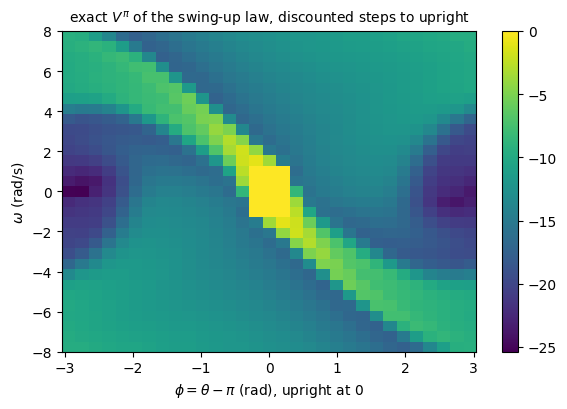

In [ ]:
M_P, L_P, B_P, G_P, U_MAX = 1.0, 1.0, 0.1, 9.81, 5.0      # the course pendulum, Utils/pendulum_sim.m


def wrap(a):
    return np.mod(a + np.pi, 2 * np.pi) - np.pi


def pend_rhs(th, om, u):
    return om, (u - B_P * om - M_P * G_P * L_P * np.sin(th)) / (M_P * L_P**2)


def rk4(th, om, u, dt):
    """One RK4 step with the torque held constant (zero-order hold), vectorised over cells."""
    k1 = pend_rhs(th, om, u)
    k2 = pend_rhs(th + dt / 2 * k1[0], om + dt / 2 * k1[1], u)
    k3 = pend_rhs(th + dt / 2 * k2[0], om + dt / 2 * k2[1], u)
    k4 = pend_rhs(th + dt * k3[0], om + dt * k3[1], u)
    return (th + dt / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0]),
            om + dt / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1]))


def build_chain(gamma=0.98, nphi=31, nom=31, ommax=8.0, dt=0.10, sigu=1.0, philim=0.30, omlim=1.2):
    """The Week 5 policy-evaluation chain. Returns a dict with P, r, term, Vpi and the grids."""
    dphi = 2 * np.pi / nphi
    phi = (np.arange(1, nphi + 1) - (nphi + 1) / 2) * dphi       # a cell centre sits on the upright
    om = np.linspace(-ommax, ommax, nom)
    dom = om[1] - om[0]
    PH, OM = np.meshgrid(phi, om, indexing="ij")
    phiv, omv = PH.ravel(order="F"), OM.ravel(order="F")          # state index s = i + nphi * j
    nS = phiv.size

    # The policy. Discrete LQR about the upright on the zero-order-hold model, Q = diag(10, 1), R = 0.5.
    A = np.array([[0.0, 1.0], [G_P / L_P, -B_P / (M_P * L_P**2)]])
    B = np.array([[0.0], [1.0 / (M_P * L_P**2)]])
    Ad = expm(A * dt)
    Bd = np.linalg.solve(A, (Ad - np.eye(2)) @ B)
    Q, R = np.diag([10.0, 1.0]), np.array([[0.5]])
    S = solve_discrete_are(Ad, Bd, Q, R)
    K = np.linalg.solve(R + Bd.T @ S @ Bd, Bd.T @ S @ Ad).ravel()  # K = (R + B'SB)^-1 B'SA
    theta = wrap(phiv + np.pi)
    E = 0.5 * M_P * L_P**2 * omv**2 + M_P * G_P * L_P * (1 - np.cos(theta))
    u = B_P * omv - 0.9 * (E - 2 * M_P * G_P * L_P) * omv          # energy shaping, friction cancelled
    stuck = (np.abs(omv) < 0.05) & (E < 2 * M_P * G_P * L_P)       # the hanging rest state: nudge it
    u[stuck] = 0.5 * U_MAX
    catch = (np.abs(phiv) < 0.5) & (np.abs(omv) < 3.0)
    u[catch] = -K[0] * phiv[catch] - K[1] * omv[catch]
    u = np.clip(u, -U_MAX, U_MAX)

    # The kernel: five disturbance values, each landing point shared bilinearly among four cells.
    zn = np.array([-2.0, -1.0, 0.0, 1.0, 2.0])
    wp = np.array([0.06, 0.24, 0.40, 0.24, 0.06])
    rows, cols, vals = [], [], []
    for z, w in zip(zn, wp / wp.sum()):
        thn, omn = rk4(theta, omv, np.clip(u + z * sigu, -U_MAX, U_MAX), dt)
        pc = wrap(thn - np.pi) / dphi + (nphi - 1) / 2               # continuous cell coordinates
        qc = (np.clip(omn, om[0], om[-1]) - om[0]) / dom
        i0 = np.floor(pc).astype(int)
        fi = pc - i0
        j0 = np.clip(np.floor(qc).astype(int), 0, nom - 2)
        fj = np.clip(qc - j0, 0.0, 1.0)
        ia, ib = np.mod(i0, nphi), np.mod(i0 + 1, nphi)              # phi is circular
        for ii, jj, ww in ((ia, j0, (1 - fi) * (1 - fj)), (ib, j0, fi * (1 - fj)),
                           (ia, j0 + 1, (1 - fi) * fj), (ib, j0 + 1, fi * fj)):
            rows.append(np.arange(nS))
            cols.append(ii + nphi * jj)
            vals.append(w * ww)
    rows, cols, vals = map(np.concatenate, (rows, cols, vals))

    term = (np.abs(phiv) <= philim) & (np.abs(omv) <= omlim)
    r = np.where(term, 0.0, -1.0)
    keep = ~term[rows] & (vals > 0)
    ti = np.flatnonzero(term)
    P = sp.csr_matrix((vals[keep], (rows[keep], cols[keep])), shape=(nS, nS))
    P = (P + sp.csr_matrix((np.ones(ti.size), (ti, ti)), shape=(nS, nS))).tocsr()   # absorbing goal
    P.sum_duplicates()
    Vpi = spsolve((sp.eye(nS) - gamma * P).tocsc(), r)                 # the exact reference
    return dict(P=P, r=r, term=term, Vpi=Vpi, gamma=gamma, nS=nS, nphi=nphi, nom=nom,
                phi=phi, om=om, dt=dt, K=K)


def make_sampler(P):
    """Per-row successor lists and cumulative probabilities, so one transition costs one lookup."""
    nS = P.shape[0]
    width = int(np.diff(P.indptr).max())
    nxt = np.zeros((nS, width), dtype=int)
    cum = np.ones((nS, width))
    for s in range(nS):
        a, b = P.indptr[s], P.indptr[s + 1]
        nxt[s, : b - a], nxt[s, b - a:] = P.indices[a:b], P.indices[b - 1]
        cum[s, : b - a] = np.cumsum(P.data[a:b])
    cum[:, -1] = 1.0
    return nxt, cum


t = time.perf_counter()
CH = build_chain(gamma=0.98)
NXT, CUM = make_sampler(CH["P"])
TERM, NT = CH["term"], np.flatnonzero(~CH["term"])
NS = CH["nS"]
MAXSTEPS = 250                                 # episode cap, never reached in practice
PHI_S = np.tile(CH["phi"], CH["nom"])          # coordinates of every state index s = i + nphi j
OM_S = np.repeat(CH["om"], CH["nphi"])
NEAR = np.flatnonzero((np.abs(PHI_S) < 0.5) & (np.abs(OM_S) < 3.0) & ~TERM)   # LQR catch region (section 7)


def sample_next(s, u):
    """Next state of every chain in s, given one uniform number per chain."""
    return NXT[s, (CUM[s] < u[:, None]).sum(axis=1)]


def rms_error(V, Vpi):
    """RMS error over the non-terminal states, one value per row of V."""
    return np.sqrt(np.mean((V[:, NT] - Vpi[NT]) ** 2, axis=1))


Vpi = CH["Vpi"]
vrms = np.sqrt(np.mean(Vpi[NT] ** 2))
print(f"chain built in {time.perf_counter() - t:.2f} s: {NS} states, {TERM.sum()} absorbing goal cells, "
      f"gamma = {CH['gamma']}, dt = {CH['dt']} s")
print(f"LQR gain of the catch region K = {CH['K'].round(2)}")
print(f"V^pi over non-terminal states: [{Vpi[NT].min():.2f}, {Vpi[NT].max():.2f}], rms {vrms:.2f}")
print(f"worst case -1/(1 - gamma) = {-1 / (1 - CH['gamma']):.0f}")

# Mean episode length from a uniformly drawn start: the unit that converts episodes to transitions.
rng = np.random.default_rng(3)
s, steps, alive = rng.choice(NT, 20_000), 0, np.ones(20_000, bool)
while alive.any():
    s[alive] = sample_next(s[alive], rng.random(alive.sum()))
    steps += alive.sum()
    alive &= ~TERM[s]
EP_LEN = steps / 20_000
print(f"mean episode length {EP_LEN:.1f} steps, so 1000 episodes are about {1000 * EP_LEN:.0f} transitions")

fig, ax = plt.subplots(figsize=(6.0, 4.2))
img = ax.imshow(Vpi.reshape(CH["nphi"], CH["nom"], order="F").T, origin="lower", aspect="auto",
                extent=[CH["phi"][0], CH["phi"][-1], CH["om"][0], CH["om"][-1]], cmap="viridis")
ax.set_xlabel(r"$\phi = \theta - \pi$ (rad), upright at 0")
ax.set_ylabel(r"$\omega$ (rad/s)")
ax.set_title(r"exact $V^\pi$ of the swing-up law, discounted steps to upright", fontsize=10)
fig.colorbar(img, ax=ax)
plt.tight_layout()
plt.show()

The bright spot at the centre is the goal. The dark bands are the states from which the
controller must first pump energy before it can climb, and they are where the value is most
negative. Every learner below starts from $V = 0$ and is scored by its RMS distance to this
picture over the 946 non-terminal cells.

## 4. Robbins–Monro on a scalar problem

Before applying stochastic approximation to policy evaluation, consider a simple scalar problem. We want to estimate a target $\theta^\star$ from noisy measurements:

$$
\theta_{k+1}=\theta_k+\alpha_k(y_k-\theta_k),
\qquad
y_k=\theta^\star+w_k,
\qquad
w_k\sim\mathcal{N}(0,0.5^2).
$$

This is the Robbins–Monro iteration for finding the root of $h(\theta)=\theta^\star-\theta$. At $k=3000$, the target changes from $1.0$ to $1.6$. Using the same noise for all three schedules, we compare their behaviour (notes, Section 2.2):

- **Decreasing step size, $\alpha_k=1/k$:** satisfies both convergence conditions, $\sum_k\alpha_k=\infty$ and $\sum_k\alpha_k^2<\infty$. However, as the step size shrinks, the estimate becomes increasingly slow to track changes in the target.
- **Fast decay, $\alpha_k=1/k^2$:** violates $\sum_k\alpha_k=\infty$. The total adjustment is finite, so the estimate may stop short of the target, even with noisy measurements.
- **Constant step size, $\alpha=0.05$:** violates $\sum_k\alpha_k^2<\infty$. The estimate continues to track changes but fluctuates around the target instead of converging exactly. For this linear problem, the stationary standard deviation is

$$
\sigma_\theta=\sqrt{\frac{\alpha\sigma_w^2}{2-\alpha}},
$$

where $\sigma_w^2=0.5^2$ is the measurement-noise variance.

The experiment illustrates the trade-off: decreasing step sizes favour convergence, while a constant step size allows continued adaptation at the cost of persistent noise.

alpha_k = 1/k   : error just before the jump +0.0096, at the end -0.2905
alpha_k = 1/k^2 : error just before the jump -0.3559, at the end -0.9557
alpha   = 0.05  : error at the end (mean of last 200) -0.0251
alpha   = 0.05  : stationary sd predicted 0.0801, measured 0.0839


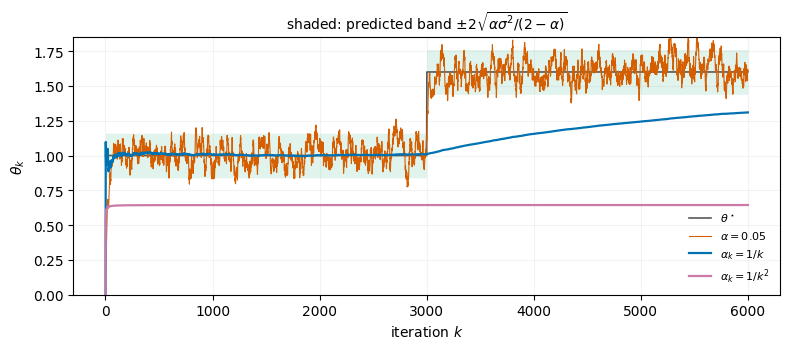

In [ ]:
K_RM, JUMP, SIG, A_CON = 6000, 3000, 0.5, 0.05
rng = np.random.default_rng(11)
target = np.where(np.arange(K_RM) < JUMP, 1.0, 1.6)
y = target + SIG * rng.standard_normal(K_RM)
th_rm, th_fast, th_con = np.zeros(K_RM), np.zeros(K_RM), np.zeros(K_RM)
for k in range(1, K_RM):
    kk = k + 1                                  # iteration count, as in the notes
    th_rm[k] = th_rm[k - 1] + (1 / kk) * (y[k] - th_rm[k - 1])
    th_fast[k] = th_fast[k - 1] + (1 / kk**2) * (y[k] - th_fast[k - 1])
    th_con[k] = th_con[k - 1] + A_CON * (y[k] - th_con[k - 1])

sd_pred = np.sqrt(A_CON * SIG**2 / (2 - A_CON))
sd_meas = th_con[int(0.6 * JUMP):JUMP].std()
print(f"alpha_k = 1/k   : error just before the jump {th_rm[JUMP - 1] - 1.0:+.4f}, at the end {th_rm[-1] - 1.6:+.4f}")
print(f"alpha_k = 1/k^2 : error just before the jump {th_fast[JUMP - 1] - 1.0:+.4f}, at the end {th_fast[-1] - 1.6:+.4f}")
print(f"alpha   = {A_CON}  : error at the end (mean of last 200) {th_con[-200:].mean() - 1.6:+.4f}")
print(f"alpha   = {A_CON}  : stationary sd predicted {sd_pred:.4f}, measured {sd_meas:.4f}")

fig, ax = plt.subplots(figsize=(8.0, 3.6))
kk = np.arange(1, K_RM + 1)
ax.fill_between(kk, target - 2 * sd_pred, target + 2 * sd_pred, color="#009E73", alpha=0.12, lw=0)
ax.plot(kk, target, color="0.35", lw=1.2, label=r"$\theta^\star$")
ax.plot(kk, th_con, color="#D55E00", lw=0.8, label=r"$\alpha = 0.05$")
ax.plot(kk, th_rm, color="#0072B2", lw=1.6, label=r"$\alpha_k = 1/k$")
ax.plot(kk, th_fast, color="#CC79A7", lw=1.6, label=r"$\alpha_k = 1/k^2$")
ax.set_xlabel("iteration $k$")
ax.set_ylabel(r"$\theta_k$")
ax.set_ylim(0, 1.85)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title(r"shaded: predicted band $\pm 2\sqrt{\alpha\sigma^2/(2-\alpha)}$", fontsize=10)
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

### Checkpoint 1

Which of the three schedules is within approximately 0.1 of the new setpoint at $k = 6000$, and why does
$\alpha_k = 1/k$, the schedule that satisfies both conditions, fall short? How do the predicted
and measured spreads of the constant-step iterate compare?

### Checkpoint 1 Answer

1. **Closest Schedule:** Only the **constant step size** ($\alpha = 0.05$) is within $0.1$ of the new setpoint ($1.6$). It continues to adapt to the change because its step size does not decay, ending with a mean error of only $-0.0251$ at $k = 6000$.

2. **Why $\alpha_k = 1/k$ falls short:**
   * While it satisfies both Robbins-Monro convergence conditions, the step size decays too rapidly in the early stages. By $k=3000$, the step size has shrunk to $0.0003$. Consequently, when the setpoint jumps to $1.6$, the update step is too small to track the change efficiently, leaving it far short at $\approx 1.31$ (error of $-0.29$).
   * *Note on $\alpha_k = 1/k^2$:* It violates $\sum \alpha_k = \infty$, meaning its total parameter change is bounded by a finite limit. It gets permanently stuck far below the initial setpoint (ending with an error of $-0.96$).

3. **Spread Comparison:**
   * The **predicted** stationary standard deviation ($\sigma_\theta = \sqrt{\frac{\alpha\sigma_w^2}{2-\alpha}}$) is **$0.0801$**.
   * The **measured** standard deviation in the stationary phase (from $k=1800$ to $k=3000$) is **$0.0839$**.
   * The theoretical and empirical spreads are in extremely close agreement, demonstrating that the noise level behaves exactly as predicted by stochastic approximation theory.

## 5. The TD(0) update

Every learner in this notebook runs as one row of a batch, so dozens of them cost little more
than one. `V` has shape `(n_chains, n_states)`, and `s`, `s_next`, `reward` and `alpha` hold one entry
per chain. Entry `V[i, s[i]]` is chain $i$'s value of its current state, and with
`rows = np.arange(len(s))` the whole column of them is `V[rows, s]`.

Write lines 5 and 6 of Algorithm 1 (notes section 2.4). The runner below has already chosen the
step size of each chain, either a constant or $1/n(x)$, so `alpha` arrives as an array.

In [ ]:
def td0_update(V, s, s_next, reward, alpha, gamma):
    """In place, for every chain i: V[i, s_i] += alpha_i * delta_i. Returns delta, shape (n_chains,)."""
    rows = np.arange(len(s))
    # ===== YOUR CODE HERE (≈2 lines) ============================
    # Goal: delta_i = r_i + gamma V[i, s'_i] - V[i, s_i], then V[i, s_i] += alpha_i delta_i, for all i
    # Hint: Algorithm 1, lines 5 and 6 (notes section 2.4); index with V[rows, s] and V[rows, s_next]
    delta = reward + gamma * V[rows, s_next] - V[rows, s]
    V[rows, s] += alpha * delta
    # ============================================================
    return delta

### A test against the hand trace of the notes

The two-state chain of the hand-trace example in notes section 2.4: $x_1 \to x_2 \to$ terminal,
reward $-1$ per transition, $\gamma = 0.9$, $\alpha = 0.5$, $V = 0$. After two episodes the notes
have $V(x_1) = -0.975$ and $V(x_2) = -0.75$.

In [ ]:
V_hand = np.zeros((1, 3))                       # states x1, x2, terminal
for episode in range(2):
    for s_, sn_ in ((0, 1), (1, 2)):
        d = td0_update(V_hand, np.array([s_]), np.array([sn_]), np.array([-1.0]), np.array([0.5]), 0.9)
        print(f"episode {episode + 1}, x{s_ + 1} -> {'x2' if sn_ == 1 else 'T '}: "
              f"delta = {d[0]:+.2f}, V = {V_hand[0, :2].round(4)}")
assert np.allclose(V_hand[0, :2], [-0.975, -0.75]), "compare with the table in notes section 2.4"
print("\nhand trace reproduced")

episode 1, x1 -> x2: delta = -1.00, V = [-0.5  0. ]
episode 1, x2 -> T : delta = -1.00, V = [-0.5 -0.5]
episode 2, x1 -> x2: delta = -0.95, V = [-0.975 -0.5  ]
episode 2, x2 -> T : delta = -0.50, V = [-0.975 -0.75 ]

hand trace reproduced


## 6. What the step size costs inside TD(0)

Four step-size rules, eight seeds each, on the pendulum chain: constant $\alpha \in \{0.30, 0.10,
0.03\}$ and the per-state Robbins–Monro schedule $\alpha_t(x) = 1/n(x)$, where $n(x)$ counts the
visits to $x$ so far.

Each chain restarts from a uniformly drawn non-terminal cell whenever it reaches the goal. All
chains take one transition per loop iteration, so the horizontal axis below is the transition
count of every learner, the unit a robot pays in. (Episodes have different lengths, so the episode
index would be a misleading clock.) The budget is $5 \times 10^5$ transitions, about 30 000
episodes or 14 hours of robot time at 10 Hz. About 30 seconds.

32 learners x 500000 transitions: 74.8 s

     alpha    at 3e+04    at 1e+05    at 3e+05    at 5e+05
      0.30        9.29        3.80        0.83        0.80
      0.10       12.10        8.75        3.67        1.47
      0.03       13.42       12.09        9.16        7.04
    1/n(x)       10.31        9.04        8.05        7.63


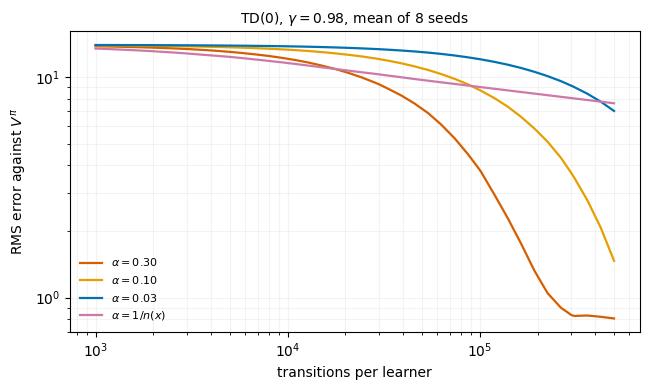

In [ ]:
def run_td0(alphas, rm, gamma, n_trans, seed, near=None, marks=(), n_eval=40):
    """Batch TD(0) on the chain. Row i uses step alphas[i], or alphas[i]/n(x) where rm[i].

    Every episode starts from a uniformly drawn non-terminal cell, or, for the rows where near[i] is
    True, from a cell of the start set NEAR of section 7.
    Returns the evaluation times (transitions), the RMS error of every row at those times, the final
    tables V and the visit counts n.
    """
    C = len(alphas)
    near = np.zeros(C, dtype=bool) if near is None else near
    rng = np.random.default_rng(seed)
    rows = np.arange(C)
    V = np.zeros((C, NS))
    n = np.zeros((C, NS))
    s = rng.choice(NT, C)
    s[near] = rng.choice(NEAR, near.sum()) if near.any() else s[near]
    steps = np.zeros(C, dtype=int)
    t_eval = np.unique(np.r_[np.geomspace(1000, n_trans, n_eval).astype(int), marks])
    err = np.zeros((C, len(t_eval)))
    k = 0
    for t in range(1, n_trans + 1):
        if (t - 1) % 10_000 == 0:               # random numbers in blocks, for speed
            U, Z = rng.random((10_000, C)), rng.standard_normal((10_000, C))
        j = (t - 1) % 10_000
        s_next = sample_next(s, U[j])
        reward = CH["r"][s] + Z[j]               # -1 per step, plus observation noise of sd 1
        n[rows, s] += 1
        alpha = np.where(rm, alphas / n[rows, s], alphas)
        td0_update(V, s, s_next, reward, alpha, gamma)
        steps += 1
        done = TERM[s_next] | (steps >= MAXSTEPS)
        if done.any():                           # new episode from a fresh start state
            s_next[done & ~near] = rng.choice(NT, (done & ~near).sum())
            if near.any():
                s_next[done & near] = rng.choice(NEAR, (done & near).sum())
            steps[done] = 0
        s = s_next
        if t == t_eval[k]:
            err[:, k] = rms_error(V, Vpi)
            k += 1
    return t_eval, err, V, n


SCHEDULES = [("0.30", 0.30, False), ("0.10", 0.10, False), ("0.03", 0.03, False), ("1/n(x)", 1.0, True)]
SEEDS = 8
COL_SA = {"0.30": "#D55E00", "0.10": "#E69F00", "0.03": "#0072B2", "1/n(x)": "#CC79A7"}


def step_size_experiment(n_trans, seed, marks):
    names = [nm for nm, _, _ in SCHEDULES]
    al = np.repeat([a for _, a, _ in SCHEDULES], SEEDS)
    rm = np.repeat([f for _, _, f in SCHEDULES], SEEDS)
    t_ev, err, _, _ = run_td0(al, rm, CH["gamma"], n_trans, seed, marks=marks)
    curves = err.reshape(len(SCHEDULES), SEEDS, -1).mean(axis=1)        # (schedule, time)
    return names, t_ev, curves


def plot_step_size(names, t_ev, curves):
    fig, ax = plt.subplots(figsize=(6.6, 4.0))
    for c, nm in enumerate(names):
        ax.loglog(t_ev, curves[c], color=COL_SA[nm], lw=1.6, label=rf"$\alpha = {nm}$")
    ax.set_xlabel("transitions per learner")
    ax.set_ylabel(r"RMS error against $V^\pi$")
    ax.set_title(rf"TD(0), $\gamma = {CH['gamma']}$, mean of {SEEDS} seeds", fontsize=10)
    ax.grid(alpha=0.15, which="both")
    ax.legend(frameon=False, fontsize=8, loc="lower left")
    plt.tight_layout()
    plt.show()


def report_step_size(names, t_ev, curves, marks):
    print(f"{'alpha':>10}" + "".join(f"{f'at {m:.3g}':>12}" for m in marks))
    for c, nm in enumerate(names):
        vals = [curves[c, np.flatnonzero(t_ev == m)[0]] for m in marks]
        print(f"{nm:>10}" + "".join(f"{v:12.2f}" for v in vals))


N_TRANS = 500_000
MARKS = (30_000, 100_000, 300_000, N_TRANS)
t = time.perf_counter()
names, t_ev, curves = step_size_experiment(N_TRANS, seed=1, marks=MARKS)
print(f"{len(SCHEDULES) * SEEDS} learners x {N_TRANS} transitions: {time.perf_counter() - t:.1f} s\n")
report_step_size(names, t_ev, curves, marks=MARKS)
plot_step_size(names, t_ev, curves)

### Checkpoint 2

Which constant step has stopped improving, and at what RMS error? Which are still falling at the
end of the budget? Where does $1/n(x)$ stand at $5 \times 10^5$ transitions, compared with the
three constant steps?

### Checkpoint 2 Answer

1. **Transitions per learner:** This represents the total cumulative state-transition steps experienced by each individual parallel agent (essentially acting as a sample-efficiency clock where each step costs 0.1s on a real robot).

2. **Which constant step stopped improving?**
   * **$\alpha = 0.30$** stopped improving early (plateauing around 100,000 transitions) at an RMS error of approximately **$0.80$**. Because its step size is large, it remains stuck at this "noise floor" fluctuating due to the variance of the updates.

3. **Which are still falling?**
   * Both **$\alpha = 0.10$** and **$\alpha = 0.03$** are still downward-sloping at $5 \times 10^5$ transitions, meaning they have not yet reached their respective noise floors and would continue to improve with a larger budget.

4. **Where does $1/n(x)$ stand?**
   * The $1/n(x)$ schedule performs **the worst** among all schedules tested, ending at an RMS error of **$7.63$**. This is much higher than all three constant steps. In TD learning, decaying the step size too quickly (which $1/n(x)$ does as states accumulate visits) prevents the algorithm from propagates values back across the chain efficiently, leaving estimates severely under-updated.

### Optional, if you finish early: the full budget of the notes

The figure in notes section 2.6 runs $2 \times 10^5$ episodes, $3.27 \times 10^6$ transitions.
Set `LONG_RUN = True` to reproduce it (about three minutes on a laptop, six in Colab).
At that budget the constant steps end at $0.82$, $0.43$ and $0.24$, with $\alpha = 0.03$ now the
best and still falling, and $1/n(x)$ ends at $6.25$, worse by a factor of 26 than the best
constant step.
The notes report $0.83$, $0.44$, $0.25$ and $6.25$ from the MATLAB run.

In [ ]:
LONG_RUN = False
if LONG_RUN:
    t = time.perf_counter()
    MARKS_L = (300_000, 1_000_000, 2_000_000, 3_270_000)
    names_L, t_L, curves_L = step_size_experiment(3_270_000, seed=1, marks=MARKS_L)
    print(f"long run: {time.perf_counter() - t:.0f} s\n")
    report_step_size(names_L, t_L, curves_L, marks=MARKS_L)
    plot_step_size(names_L, t_L, curves_L)

## 7. Coverage: the states the data never reach

So far, every learner has restarted from a uniformly sampled state. A simulator makes this easy; a real robot rarely can. To see why this matters, consider a robot tested only near balance. Each episode starts in the LQR controller's catch region, defined by

$$
|\phi| < 0.5, \qquad |\omega| < 3,
$$

excluding goal cells.

The controller catches some episodes immediately. In others, torque saturation and actuator disturbances push the pendulum outside the catch region, forcing it to swing around before recovering. We run TD(0), with a step size of
$
\alpha = 0.30,
$
and eight random seeds for
$
2\times 10^5
$
transitions under two initial-state distributions: restricted starts in the catch region and uniform starts across the state space.

The convergence theorem in Section 2.4 assumes that every state is visited infinitely often; a condition the notes interpret as **coverage**. What happens when the data never visit a state? This experiment reveals which values can be learned from the observed transitions and which remain unlearned.

*Runtime: about 12 seconds.*

16 learners x 200000 transitions: 37.4 s

start set: 40 cells near the upright, out of 946 non-terminal cells
near-upright starts: 30.4% of the non-terminal cells visited at least once
uniform starts     : 100.0%

              RMS error against V^pi  near starts   uniform
      cells the near learner visited         3.33      0.89
              cells it never visited        15.09      1.37
              all non-terminal cells        12.71      1.24

rms of V^pi itself over the never-visited cells: 15.09; largest |V| the near learners hold there: 0.0


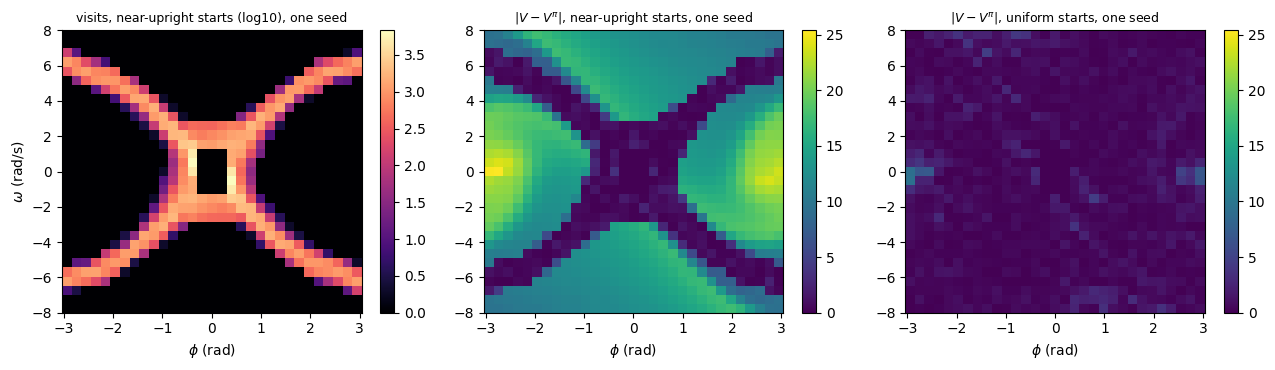

In [ ]:
N_COV = 200_000

t = time.perf_counter()
near_rows = np.repeat([True, False], SEEDS)     # first eight learners near the upright, then uniform
_, _, V_cov, n_cov = run_td0(np.full(2 * SEEDS, 0.30), np.zeros(2 * SEEDS, dtype=bool), CH["gamma"],
                             N_COV, seed=2, near=near_rows)
V_near, n_near, V_unif, n_unif = V_cov[:SEEDS], n_cov[:SEEDS], V_cov[SEEDS:], n_cov[SEEDS:]
print(f"{2 * SEEDS} learners x {N_COV} transitions: {time.perf_counter() - t:.1f} s\n")


def rms(x):
    return np.sqrt(np.mean(x**2))


seen = n_near[:, NT] > 0                        # (seed, non-terminal state)
err_near = V_near[:, NT] - Vpi[NT]
err_unif = V_unif[:, NT] - Vpi[NT]
print(f"start set: {NEAR.size} cells near the upright, out of {NT.size} non-terminal cells")
print(f"near-upright starts: {100 * seen.mean():.1f}% of the non-terminal cells visited at least once")
print(f"uniform starts     : {100 * (n_unif[:, NT] > 0).mean():.1f}%\n")
print(f"{'RMS error against V^pi':>36} {'near starts':>12} {'uniform':>9}")
print(f"{'cells the near learner visited':>36} {rms(err_near[seen]):12.2f} {rms(err_unif[seen]):9.2f}")
print(f"{'cells it never visited':>36} {rms(err_near[~seen]):12.2f} {rms(err_unif[~seen]):9.2f}")
print(f"{'all non-terminal cells':>36} {rms(err_near):12.2f} {rms(err_unif):9.2f}")
Vpi_rows = np.broadcast_to(Vpi[NT], seen.shape)
print(f"\nrms of V^pi itself over the never-visited cells: {rms(Vpi_rows[~seen]):.2f}; "
      f"largest |V| the near learners hold there: {np.abs(V_near[:, NT][~seen]).max():.1f}")


def on_grid(v):
    return v.reshape(CH["nphi"], CH["nom"], order="F").T


ext = [CH["phi"][0], CH["phi"][-1], CH["om"][0], CH["om"][-1]]
vmax = np.abs(Vpi).max()
fig, axes = plt.subplots(1, 3, figsize=(13.0, 3.8))
panels = [(np.log10(1 + n_near[0]), "visits, near-upright starts (log10)", "magma", None),
          (np.abs(V_near[0] - Vpi), r"$|V - V^\pi|$, near-upright starts", "viridis", vmax),
          (np.abs(V_unif[0] - Vpi), r"$|V - V^\pi|$, uniform starts", "viridis", vmax)]
for ax, (img_, title, cm, top) in zip(axes, panels):
    im = ax.imshow(on_grid(img_), origin="lower", aspect="auto", extent=ext, cmap=cm, vmin=0, vmax=top)
    ax.set_title(title + ", one seed", fontsize=9)
    ax.set_xlabel(r"$\phi$ (rad)")
    fig.colorbar(im, ax=ax)
axes[0].set_ylabel(r"$\omega$ (rad/s)")
plt.tight_layout()
plt.show()

### Checkpoint 3

With near-upright starts, what fraction of the non-terminal cells did the learners ever visit,
and what is the RMS error on the cells they never visited? Why is that error the size of $V^\pi$
there, and which assumption of the convergence theorem has failed?

### Checkpoint 3 Answer

1. **Visited Fraction:** The learners only visited **$30.4\%$** of the non-terminal states.
2. **RMS Error on never-visited cells:** The RMS error on the unvisited cells is **$15.09$**.
3. **Why the error is the size of $V^\pi$:** Since these states are never visited, their value estimates are never updated and remain at their initialization value of $0$. The error at each of these states is $V(x) - V^\pi(x) = 0 - V^\pi(x) = -V^\pi(x)$. Thus, the RMS error over these states is mathematically identical to the RMS value of the true $V^\pi$ itself ($15.09$).
4. **Which assumption failed:** The assumption of **coverage** (or infinite exploration) has failed. The convergence theorem of TD learning requires that **every state must be visited infinitely often** ($n(x) \to \infty$ for all $x$). Starting only in the restricted LQR catch region makes the probability of reaching far-away states zero, breaking this assumption.

## 8. The Monte Carlo target and the TD target, side by side

Monte Carlo updates $V(x_t)$ towards the observed return $G_t$, an unbiased target regardless of the current value estimates. TD(0), by contrast, updates it towards the one-step target

$$
r_{t+1}+\gamma V(x_{t+1}),
$$

which depends on the current estimate of the next state's value.

To compare the two targets directly, without the effects of learning, the cell below uses the exact value function $V^\pi$ to construct the TD target. It then samples both targets 20,000 times from the chain's worst state (notes, Section 3.2), allowing us to compare their variability while holding the value estimates fixed at the truth.

worst state: V^pi = -25.38, mean episode length from it 36.1 steps

Monte Carlo return G_t     : mean -25.38, sd 6.36
TD target r + gamma V^pi(x'): mean -25.39, sd 1.52
variance ratio 17.6


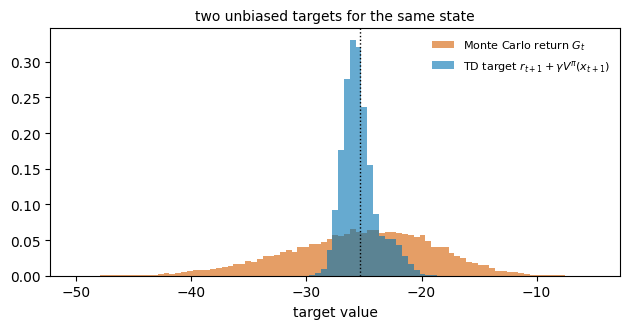

In [ ]:
s0 = NT[np.argmin(Vpi[NT])]
N_MC = 20_000
rng = np.random.default_rng(99)
s = np.full(N_MC, s0)
G, disc, length = np.zeros(N_MC), np.ones(N_MC), np.zeros(N_MC)
alive = np.ones(N_MC, bool)
td_target = None
for step in range(MAXSTEPS):
    rew = CH["r"][s] + rng.standard_normal(N_MC)
    s_new = sample_next(s, rng.random(N_MC))
    if step == 0:
        td_target = rew + CH["gamma"] * Vpi[s_new]          # one sampled reward, then the table
    G += alive * disc * rew                                 # the whole sampled episode
    disc *= CH["gamma"]
    length += alive
    s = np.where(alive, s_new, s)
    alive &= ~TERM[s]
    if not alive.any():
        break

print(f"worst state: V^pi = {Vpi[s0]:.2f}, mean episode length from it {length.mean():.1f} steps\n")
print(f"Monte Carlo return G_t     : mean {G.mean():+.2f}, sd {G.std():.2f}")
print(f"TD target r + gamma V^pi(x'): mean {td_target.mean():+.2f}, sd {td_target.std():.2f}")
print(f"variance ratio {G.var() / td_target.var():.1f}")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
bins = np.linspace(-50, -5, 90)
ax.hist(G, bins=bins, color="#D55E00", alpha=0.6, density=True, label=r"Monte Carlo return $G_t$")
ax.hist(td_target, bins=bins, color="#0072B2", alpha=0.6, density=True,
        label=r"TD target $r_{t+1} + \gamma V^\pi(x_{t+1})$")
ax.axvline(Vpi[s0], color="k", lw=1.0, ls=":")
ax.set_xlabel("target value")
ax.legend(frameon=False, fontsize=8)
ax.set_title("two unbiased targets for the same state", fontsize=10)
plt.tight_layout()
plt.show()

### Checkpoint 4

Both targets have the correct mean at the worst state. What are their standard deviations, and
roughly what is the ratio of their variances? Where does the extra spread of $G_t$ come from?

### Checkpoint 4 Answer

1. **Standard Deviations & Variance Ratio:**
   * **Monte Carlo Return ($G_t$):** Standard deviation of **$6.36$**
   * **TD Target ($r + \gamma V^\pi$):** Standard deviation of **$1.52$**
   * **Variance Ratio:** **$17.6$** ($G_t$ has nearly 18 times more variance than the TD target).

2. **How to Read the Graph (Y-axis):**
   * The y-axis represents **probability density**. It is normalized so that the total area of the histogram bars sums to $1.0$, representing the relative likelihood of sampling each target value.

3. **Source of the Extra Spread:**
   * The massive extra spread of $G_t$ does not come from estimation errors, as $V$ is held fixed at the exact truth $V^\pi$.
   * Instead, the difference is purely mathematical: the TD target only rolls out **one single step** of real-world noise (one noisy reward $r_{t+1}$ and one stochastic transition to $x_{t+1}$), bootstrapping the rest from the deterministic table.
   * The Monte Carlo target, by contrast, accumulates random transition noise and reward noise across the **entire remaining episode** (averaging 36 steps from the worst state). Summing these independent random variables across many steps causes the variance to add up, resulting in a highly noisy target.

## 9. TD($\lambda$) with replacing traces

Algorithm 2 (notes section 4.2) keeps one trace per state, decays all of them by $\gamma\lambda$
every step, sets the trace of the current state to 1, and applies $\alpha\,\delta_t\,e(x)$ to every
state. A dense trace over 961 states for 400 learners would cost far more than the update itself,
so the notebook keeps the list of active states the notes recommend, one slot per step of the
current episode:

- `hist[i, j]` is the state chain $i$ visited at step $j$ of its episode (empty slots hold a
  dummy index), and `e[i, j]` is the trace attached to that slot;
- slot `t[i]` is the current step, and the runner has already written `hist[i, t[i]] = s[i]`.

A state visited twice in one episode sits in two slots. Under the **replacing** convention its
trace is reset to 1, so the older slot must lose its trace. (Keeping both would give the
accumulating trace, whose value is the sum of the two slots.) The pre-written `apply_traces`
performs line 7, the update $V(x) \mathrel{+}= \alpha\delta_t\,e(x)$ over every slot with a
nonzero trace.

Write lines 5 and 6 of Algorithm 2, then call `apply_traces`. The episode is reset by the runner,
which clears `e` and `hist` when a chain reaches the goal.

In [ ]:
DUMMY = NS                                       # V carries one extra column for empty slots


def apply_traces(V, e, hist, step):
    """Line 7 of Algorithm 2: V[i, hist[i, j]] += step[i] * e[i, j] over all slots with e > 0."""
    live = np.where(e > 0.0, hist, V.shape[1] - 1)   # each real state appears at most once per row
    flat = (np.arange(V.shape[0]) * V.shape[1])[:, None] + live
    V.reshape(-1)[flat] += step[:, None] * e


def td_lambda_update(V, e, hist, s, s_next, t, reward, alpha, gamma, lam):
    """One step of TD(lambda) with replacing traces for every chain, in place. Returns delta."""
    rows = np.arange(len(s))
    # ===== YOUR CODE HERE (≈5 lines) ============================
    # Goal: delta as in TD(0); e <- gamma*lam*e; zero the older slots holding s; e[i, t_i] = 1;
    #       then apply_traces(V, e, hist, alpha * delta). Modify e in place (e *= ..., e[...] = ...),
    #       because the runner passes a view and reads the traces back from it.
    # Hint: Algorithm 2, lines 5 to 7 (notes section 4.2); gamma and lam are per-chain arrays, so
    #       broadcast them with [:, None]; the slots holding s are where hist == s[:, None]
    delta = reward + gamma * V[rows, s_next] - V[rows, s]

    # 1. Decay the traces in-place
    e *= (gamma * lam)[:, None]

    # 2. Replacing traces: zero out older slots that recorded the current state s
    e[hist == s[:, None]] = 0.0

    # 3. Set the current step's trace to 1.0
    e[rows, t] = 1.0

    # 4. Apply updates to the value function
    apply_traces(V, e, hist, alpha * delta)
    # ============================================================
    return delta

### Two tests

The first is the hand trace of TD($\lambda$) in notes section 4.2: the same two-state chain,
$\lambda = 0.5$, one episode, after which the notes have $V(x_1) = -0.725$ and $V(x_2) = -0.5$.
The second runs a random episode on the pendulum chain with $\lambda = 0$ and checks it against
your TD(0) step for step, since Algorithm 2 must collapse onto Algorithm 1.

In [ ]:
def new_traces(C, width=MAXSTEPS):
    return np.zeros((C, width)), np.full((C, width), DUMMY)


V_hand = np.zeros((1, 4))                        # x1, x2, terminal, dummy column
e, hist = new_traces(1, 4)
for t_, (s_, sn_) in enumerate(((0, 1), (1, 2))):
    hist[0, t_] = s_
    d = td_lambda_update(V_hand, e, hist, np.array([s_]), np.array([sn_]), np.array([t_]),
                         np.array([-1.0]), np.array([0.5]), np.array([0.9]), np.array([0.5]))
    print(f"x{s_ + 1}: delta = {d[0]:+.2f}, traces {e[0, :2].round(2)}, V = {V_hand[0, :2].round(4)}")
assert np.allclose(V_hand[0, :2], [-0.725, -0.5]), "compare with the table in notes section 4.2"

rng = np.random.default_rng(7)
V_a, V_b = np.zeros((1, NS)), np.zeros((1, NS + 1))
e, hist = new_traces(1)
s = np.array([rng.choice(NT)])
for t_ in range(MAXSTEPS):
    s_next = sample_next(s, rng.random(1))
    rew = CH["r"][s] + rng.standard_normal(1)
    hist[0, t_] = s[0]
    td0_update(V_a, s, s_next, rew, np.array([0.3]), np.array([0.98]))
    td_lambda_update(V_b, e, hist, s, s_next, np.array([t_]), rew, np.array([0.3]),
                     np.array([0.98]), np.array([0.0]))
    s = s_next
    if TERM[s[0]]:
        break
assert np.allclose(V_a, V_b[:, :NS]), "with lambda = 0 TD(lambda) must reproduce TD(0)"
print(f"\nlambda = 0 reproduces TD(0) over a {t_ + 1}-step episode")

x1: delta = -1.00, traces [1. 0.], V = [-0.5  0. ]
x2: delta = -1.00, traces [0.45 1.  ], V = [-0.725 -0.5  ]

lambda = 0 reproduces TD(0) over a 15-step episode


## 10. The joint sweep over $\alpha$ and $\lambda$

Every pair of $\lambda \in \{0, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 1\}$ and
$\alpha \in \{0.1, 0.2, 0.3, 0.4, 0.6\}$, ten seeds each, so 400 learners run side by side on the
$\gamma = 0.98$ chain. The budget is 79 350 transitions per learner, the 5000 episodes of notes section 4.3, which is 2.2 hours of robot time
at 10 Hz. The score is the final RMS error averaged over seeds. About 25 seconds.

400 learners x 79350 transitions: 80.9 s

mean final RMS error, rows lambda, columns alpha
 lambda     0.1     0.2     0.3     0.4     0.6   best alpha
   0.00    9.64    6.85    5.00    3.74    2.47       0.6
   0.30    8.50    5.49    3.68    2.63    1.87       0.6
   0.50    7.43    4.51    2.96    2.20    1.67       0.6
   0.70    6.00    3.43    2.26    1.76    1.66       0.6
   0.80    5.17    2.89    2.01    1.79    1.82       0.4
   0.90    4.39    2.54    1.96    1.88    2.19       0.4
   0.95    4.01    2.49    2.09    2.23    2.73       0.3
   1.00    3.73    2.69    2.65    2.89    3.58       0.3

standard error of a cell mean: 0.01 to 0.05
best pair: lambda = 0.7, alpha = 0.6, RMS 1.66 = 12% of rms V^pi
TD(0) at its best alpha 2.47 (1.49x), TD(1) at its best alpha 2.65 (1.60x)


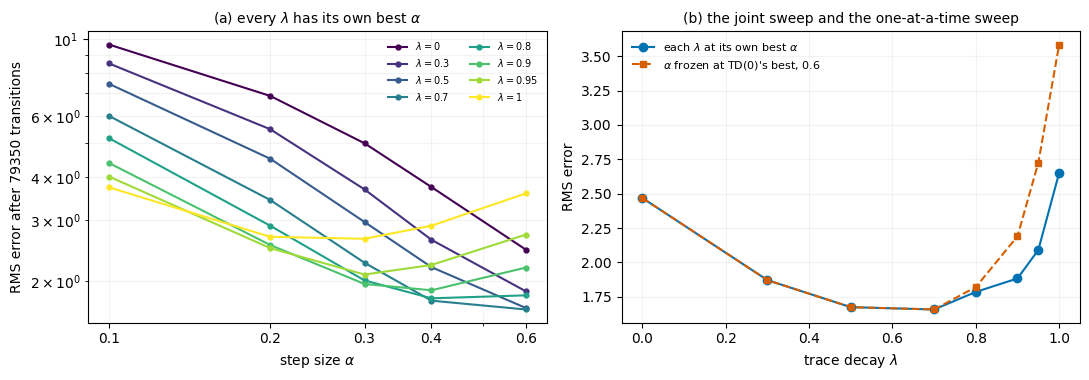

In [ ]:
def run_td_lambda(alphas, lams, gamma, n_trans, seed):
    """Batch TD(lambda), replacing traces. Returns the final RMS error of every row."""
    C = len(alphas)
    rng = np.random.default_rng(seed)
    rows = np.arange(C)
    V = np.zeros((C, NS + 1))
    e, hist = new_traces(C)
    gam = np.full(C, gamma)
    s = rng.choice(NT, C)
    t = np.zeros(C, dtype=int)                  # step index inside the current episode
    for k in range(n_trans):
        if k % 10_000 == 0:
            U, Z = rng.random((10_000, C)), rng.standard_normal((10_000, C))
        j = k % 10_000
        s_next = sample_next(s, U[j])
        hist[rows, t] = s
        w = t.max() + 1                         # only the slots some episode has reached so far
        td_lambda_update(V, e[:, :w], hist[:, :w], s, s_next, t, CH["r"][s] + Z[j], alphas, gam, lams)
        t += 1
        done = TERM[s_next] | (t >= MAXSTEPS)
        if done.any():                          # new episode: clear the trace list
            e[done], hist[done], t[done] = 0.0, DUMMY, 0
            s_next[done] = rng.choice(NT, done.sum())
        s = s_next
    return rms_error(V[:, :NS], Vpi)


LAMS = np.array([0.0, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 1.0])
ALPS = np.array([0.1, 0.2, 0.3, 0.4, 0.6])
SEEDS_L, N_TRANS_L = 10, 79_350
LL, AA = np.meshgrid(LAMS, ALPS, indexing="ij")

t = time.perf_counter()
final = run_td_lambda(np.repeat(AA.ravel(), SEEDS_L), np.repeat(LL.ravel(), SEEDS_L), 0.98, N_TRANS_L, seed=5)
surf = final.reshape(len(LAMS), len(ALPS), SEEDS_L)
R, R_sd = surf.mean(axis=2), surf.std(axis=2) / np.sqrt(SEEDS_L)
print(f"{surf.size} learners x {N_TRANS_L} transitions: {time.perf_counter() - t:.1f} s\n")

print("mean final RMS error, rows lambda, columns alpha")
print(f"{'lambda':>7}" + "".join(f"{a:8.1f}" for a in ALPS) + "   best alpha")
for i, lam in enumerate(LAMS):
    print(f"{lam:7.2f}" + "".join(f"{v:8.2f}" for v in R[i]) + f"{ALPS[R[i].argmin()]:10.1f}")
best = R.min(axis=1)
ib = best.argmin()
print(f"\nstandard error of a cell mean: {R_sd.min():.2f} to {R_sd.max():.2f}")
print(f"best pair: lambda = {LAMS[ib]}, alpha = {ALPS[R[ib].argmin()]}, RMS {best[ib]:.2f} "
      f"= {100 * best[ib] / vrms:.0f}% of rms V^pi")
print(f"TD(0) at its best alpha {best[0]:.2f} ({best[0] / best[ib]:.2f}x), "
      f"TD(1) at its best alpha {best[-1]:.2f} ({best[-1] / best[ib]:.2f}x)")

fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.9))
cmap = plt.get_cmap("viridis")
for i, lam in enumerate(LAMS):
    axes[0].plot(ALPS, R[i], "-o", ms=3.5, color=cmap(i / (len(LAMS) - 1)), label=rf"$\lambda = {lam:g}$")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xticks(ALPS, [f"{a:g}" for a in ALPS])
axes[0].set_xlabel(r"step size $\alpha$")
axes[0].set_ylabel(f"RMS error after {N_TRANS_L} transitions")
axes[0].legend(frameon=False, fontsize=7, ncol=2)
axes[0].set_title(r"(a) every $\lambda$ has its own best $\alpha$", fontsize=10)
axes[1].plot(LAMS, best, "-o", color="#0072B2", label=r"each $\lambda$ at its own best $\alpha$")
ia0 = R[0].argmin()                              # TD(0)'s best step size, then frozen
axes[1].plot(LAMS, R[:, ia0], "--s", ms=4, color="#D55E00",
             label=rf"$\alpha$ frozen at TD(0)'s best, {ALPS[ia0]:g}")
axes[1].set_xlabel(r"trace decay $\lambda$")
axes[1].set_ylabel("RMS error")
axes[1].legend(frameon=False, fontsize=8)
axes[1].set_title("(b) the joint sweep and the one-at-a-time sweep", fontsize=10)
for ax in axes:
    ax.grid(alpha=0.15, which="both")
plt.tight_layout()
plt.show()

### Checkpoint 5

With each $\lambda$ at its own best step size (the blue curve), where is the best $\lambda$, and
how much worse are the two endpoints, TD(0) and TD(1)? What does the shape of the curve say about
the two extremes?

### Checkpoint 5 Answer

1. **Best $\lambda$ and Endpoint Performance:**
   * The **best parameter** is **$\lambda = 0.7$** (with an optimal step size of $\alpha = 0.6$), reaching a minimum RMS error of **$1.66$** (only $12\%$ of the RMS value of $V^\pi$).
   * **TD(0) ($\lambda = 0.0$):** At its best step size ($\alpha = 0.6$), it achieves an RMS error of **$2.47$** ($1.49\times$ worse than the optimal middle-ground).
   * **TD(1) ($\lambda = 1.0$):** At its best step size ($\alpha = 0.3$), it achieves an RMS error of **$2.65$** ($1.60\times$ worse than the optimal middle-ground).

2. **What the Curve's Shape Says about the Extremes:**
   * The distinct **U-shape** of the blue curve (plotting the performance of each $\lambda$ tuned at its own best $\alpha$) illustrates a classic **bias-variance tradeoff**:
     * **At the left extreme ($\lambda = 0.0$):** The update targets have low variance but high **bias** because bootstrap values propagate extremely slowly, requiring many steps to pass rewards backward.
     * **At the right extreme ($\lambda = 1.0$ / Monte Carlo):** The targets are unbiased but carry extreme **variance**, as noise from actuator disturbances and reward observations accumulates over entire episodes.
     * **In the middle ($\lambda = 0.7$):** We find the optimal balance, where multi-step updates propagate rewards rapidly while bootstrapping safely cuts off the high-variance tail of the rollouts.

### Checkpoint 6

How does the best $\alpha$ move as $\lambda$ grows? Now read the orange curve, the sweep a
one-parameter-at-a-time workflow would produce by freezing $\alpha$ at TD(0)'s best value and
moving $\lambda$ alone. What does it conclude about $\lambda = 0.95$ compared with TD(0), and is
that conclusion right?

### Checkpoint 6 Answer

1. **Movement of Best $\alpha$ as $\lambda$ Grows:**
   * As $\lambda$ increases, the **optimal step size $\alpha$ decreases monotonically**:
     * For $\lambda \in [0.0, 0.7]$, the best $\alpha$ is **$0.6$**.
     * For $\lambda \in [0.8, 0.9]$, the best $\alpha$ drops to **$0.4$**.
     * For $\lambda = 1.0$ (Monte Carlo), the best $\alpha$ decreases further to **$0.3$**.
   * **Why:** Larger values of $\lambda$ aggregate stochastic transitions and rewards over a longer horizon, significantly increasing target variance. To avoid unstable value updates under this higher noise floor, the learner must use a smaller, more conservative step size $\alpha$.

2. **The One-at-a-Time Sweep (Orange Curve) Fallacy:**
   * If we freeze $\alpha$ at TD(0)'s optimal value ($0.6$) and sweep $\lambda$ alone (the dashed orange curve), the error increases sharply for high values of $\lambda$.
   * This workflow concludes that **$\lambda = 0.95$ is worse than TD(0)** ($2.73$ RMS error vs. $2.47$).
   * **Is this conclusion correct?** No, it is completely incorrect. When the parameters are **tuned jointly** (the blue curve), we see that $\lambda = 0.95$ paired with its optimal $\alpha = 0.3$ yields an RMS error of **$2.09$**, which is substantially better than TD(0). The one-at-a-time workflow failed because it evaluated a high-variance target using a step size that was far too aggressive, causing learning to destabilize.

## 11. Analysis

A few sentences each. They are not quizzed, and they come back in later weeks.

1. Section 6 evaluated a policy that never changes. In Week 6 the policy is improved after every
   few evaluations, so the target $V^\pi$ itself moves. Which of today's step-size rules would you
   pick for that setting, and what does the adaptive-control analogy of notes section 2.6 (a
   forgetting factor in recursive least squares) say about the price?

2. The best TD($\lambda$) learner reached about $12\%$ RMS error after 2.2 hours of robot time,
   for one controller handed to us on 961 states. The linear solve of section 3 took a fraction
   of a second, given the model. What does that comparison say about where a model, even an
   approximate one, is worth its cost? Week 11 returns to it with learned dynamics.

3. Section 7 could fix its coverage problem by choosing the start states, because the
   simulator lets it. Name two ways to get data into the never-visited cells on a real pendulum,
   and what each one costs (in safety, in robot time, or in modelling effort). Week 12 makes
   coverage the central problem of offline RL, where no new data can be collected at all.